<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">4. Treatment Effect Analysis</h2>

**Goal (Objective 1):** estimate how much each Urea strategy changes yield, test whether the differences are statistically significant, and check whether the answer changes by mega-environment or season.

**Why a mixed-effects model?** The four plots in a field share soil, rainfall and management. Treating 1,590 plots as independent would overstate precision. A random intercept for each field-season unit means treatment effects are estimated mostly *within* fields:

`yield ~ treatment + season + mega-environment + (1 | field-season)`

The model code is in [`src/maize/analysis.py`](../src/maize/analysis.py) and uses `statsmodels.MixedLM`.

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown come from the **synthetic sample** in `01_Data/sample/`, which has the same structure and data-quality problems as the real data. The numbers illustrate the method; they are not Evergreen's actual results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, analysis, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" else "synthetic sample (01_Data/sample)")

Data source: synthetic sample (01_Data/sample)


In [2]:
_, combined = data.build_combined(MODE)
df = data.analysis_frame(combined)
te = analysis.treatment_effects(df)
print(f"Model: {te['n_obs']} plots in {te['n_groups']} field-season units")

Model: 1582 plots in 397 field-season units


## 1. Adjusted mean yields

Adjusted means average the model's predictions over the observed mix of seasons and environments, as if every plot had received that treatment.

In [3]:
te["adjusted_means"][["label", "n_plots", "adjusted_mean", "ci_low", "ci_high"]]

,label,n_plots,adjusted_mean,ci_low,ci_high
0,"A: 50 kg/ha, all at V6",397,4.942,4.752,5.131
1,"B: 100 kg/ha, planting + V6",392,4.994,4.803,5.184
2,"C: 100 kg/ha, V6 + V10",397,5.440,5.250,5.630
3,"D: 100 kg/ha, all at V6",396,5.490,5.300,5.680


## 2. Gains over the 50 kg/ha baseline

In [4]:
te["gains"][["label", "gain_vs_baseline", "ci_low", "ci_high", "gain_pct", "p_holm", "significant"]]

,label,gain_vs_baseline,ci_low,ci_high,gain_pct,p_holm,significant
0,"B: 100 kg/ha, planting + V6",0.052,-0.153,0.257,1.052,1.000e+00,False
1,"C: 100 kg/ha, V6 + V10",0.498,0.294,0.702,10.087,8.352e-06,True
2,"D: 100 kg/ha, all at V6",0.548,0.344,0.753,11.099,8.375e-07,True


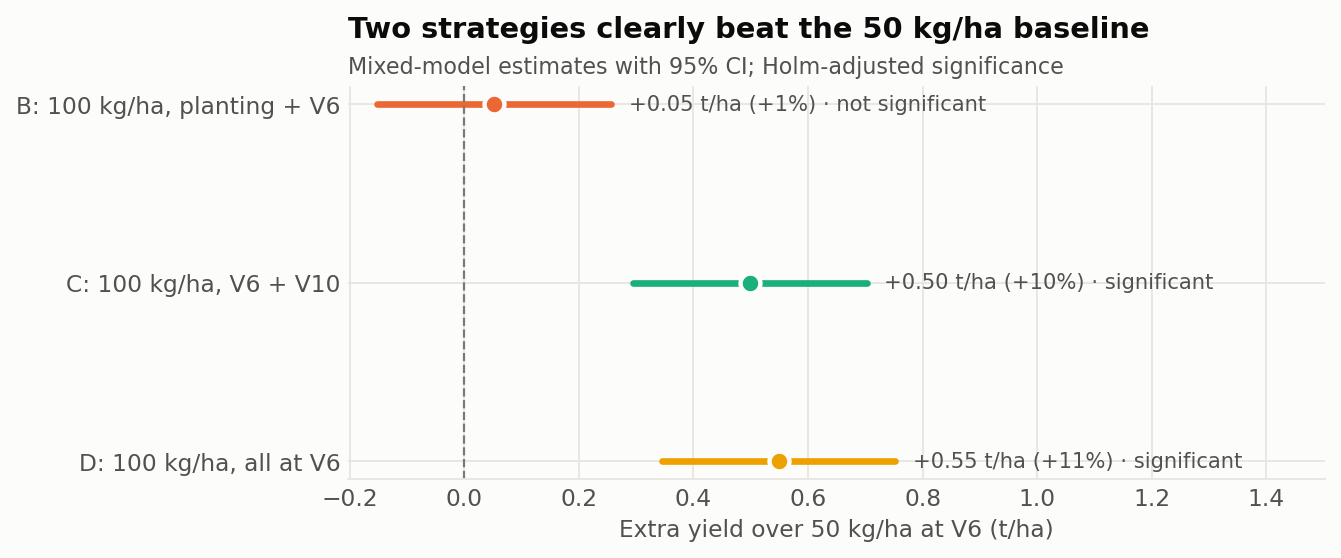

In [5]:
plotting.treatment_gains(te["gains"], OUT.figures / "treatment_gains_vs_baseline.png")
display(Image(OUT.figures / "treatment_gains_vs_baseline.png", width=760))

## 3. All pairwise comparisons

Six comparisons, Holm-adjusted to control the chance of any false positive.

In [6]:
te["pairwise"][["label", "difference_b_minus_a", "ci_low", "ci_high", "p_holm", "significant"]]

,label,difference_b_minus_a,ci_low,ci_high,p_holm,significant
0,B · 100 kg Plant+V6 vs A · 50 kg V6,0.052,-0.153,0.257,1.000e+00,False
1,C · 100 kg V6+V10 vs A · 50 kg V6,0.498,0.294,0.702,8.352e-06,True
2,D · 100 kg V6 vs A · 50 kg V6,0.548,0.344,0.753,8.375e-07,True
3,C · 100 kg V6+V10 vs B · 100 kg Plant+V6,0.446,0.242,0.651,5.784e-05,True
4,D · 100 kg V6 vs B · 100 kg Plant+V6,0.496,0.292,0.701,8.352e-06,True
5,D · 100 kg V6 vs C · 100 kg V6+V10,0.050,-0.154,0.254,1.000e+00,False


**Reading the results**
* **D (all at V6)** and **C (V6 + V10)** both beat the baseline by about 0.5 t/ha, and they are statistically indistinguishable from each other.
* **B (planting + V6)** is not significantly better than the baseline and is clearly worse than C and D. The extra Urea pays off only when it is applied at V6 or later. Nitrogen applied at planting, before the crop can take it up, is likely lost to leaching.

## 4. Does the effect change by mega-environment or season?

Likelihood-ratio tests compare the model with and without a treatment × environment (or × season) interaction. Both are fitted by maximum likelihood.

In [7]:
pd.DataFrame([analysis.interaction_test(df, "meg_env"), analysis.interaction_test(df, "season")])

,interaction,lr_statistic,df,p_value
0,Treatment x meg_env,15.358,9,0.082
1,Treatment x season,10.659,6,0.100


Neither interaction is significant at 5% (the environment test, p ≈ 0.08, is the closer of the two). The data does not support different recommendations for different environments or seasons, and the pooled estimate is the most precise basis for advice.

## 5. Best treatment in each mega-environment

The brief asks for the best treatment per mega-environment, so a separate model is fitted within each one. These estimates are less precise than the pooled one. The implausible yield is excluded here because, in a single environment's model, it distorts the Transitional estimates.

In [8]:
per_env = analysis.per_environment(df[~df["flag_implausible_yield"]].copy())
best = per_env[per_env["is_best"]][["meg_env", "n_fields", "label", "gain_vs_baseline", 
                                    "ci_low", "ci_high", "p_holm_vs_baseline", "best_vs_runner_up_diff",
                                    "best_vs_runner_up_p_holm"]]
best

,meg_env,n_fields,label,gain_vs_baseline,ci_low,ci_high,p_holm_vs_baseline,best_vs_runner_up_diff,best_vs_runner_up_p_holm
3,Highlands,142,"D: 100 kg/ha, all at V6",0.501,0.316,0.686,5.421e-07,0.214,0.046
7,Low-Mid-Dry,114,"D: 100 kg/ha, all at V6",0.594,0.387,0.800,1.124e-07,0.244,0.045
11,Low-Mid-Wet,77,"D: 100 kg/ha, all at V6",0.624,0.347,0.901,5.915e-05,0.131,0.707
15,Transitional,64,"D: 100 kg/ha, all at V6",0.482,0.227,0.737,1.301e-03,0.005,0.968


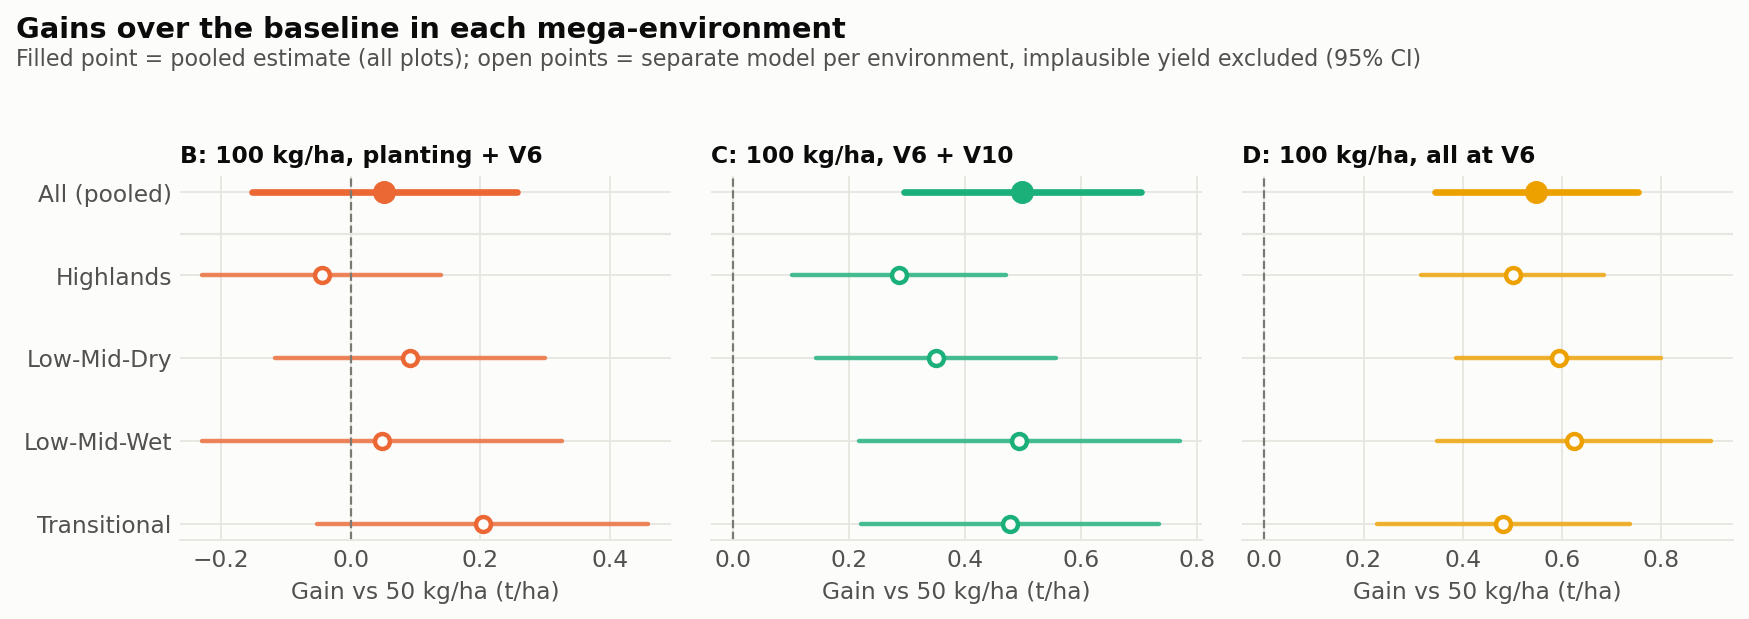

label,"A: 50 kg/ha, all at V6","B: 100 kg/ha, planting + V6","C: 100 kg/ha, V6 + V10","D: 100 kg/ha, all at V6"
meg_env,,,,
Highlands,0.0,-0.04,0.29,0.50
Low-Mid-Dry,0.0,0.09,0.35,0.59
Low-Mid-Wet,0.0,0.05,0.49,0.62
Transitional,0.0,0.20,0.48,0.48


In [9]:
plotting.per_environment_gains(per_env, te["gains"], OUT.figures / "per_environment_gains.png")
display(Image(OUT.figures / "per_environment_gains.png", width=950))
per_env.pivot(index="meg_env", columns="label", values="gain_vs_baseline").round(2)

**D ranks first in all four mega-environments**, and its gain over the baseline is significant in each.
* In the **Highlands** and **Low-Mid-Dry**, D also beats C, by about 0.2 t/ha (p ≈ 0.05).
* In **Low-Mid-Wet** and **Transitional**, D and C are statistically tied.
* **Low-Mid-Wet** and **Low-Mid-Dry** respond most strongly to the extra Urea (about 0.6 t/ha). B gives no significant gain anywhere.

## 6. Sensitivity to the implausible yield (50.1 t/ha)

In [10]:
analysis.outlier_sensitivity(df)[
    ["label", "gain_all_plots", "p_holm_all_plots", "gain_without_implausible", 
     "p_holm_without_implausible", "change"]]

,label,gain_all_plots,p_holm_all_plots,gain_without_implausible,p_holm_without_implausible,change
0,"B: 100 kg/ha, planting + V6",0.052,1.000e+00,0.052,3.580e-01,4.820e-04
1,"C: 100 kg/ha, V6 + V10",0.498,8.352e-06,0.375,1.742e-10,-1.234e-01
2,"D: 100 kg/ha, all at V6",0.548,8.375e-07,0.548,3.483e-21,-2.438e-04


D's estimate does not change. C's drops by about 0.12 t/ha, because the suspect plot is a C plot. B stays small and non-significant either way. The recommendation is robust.

## 7. Model diagnostics

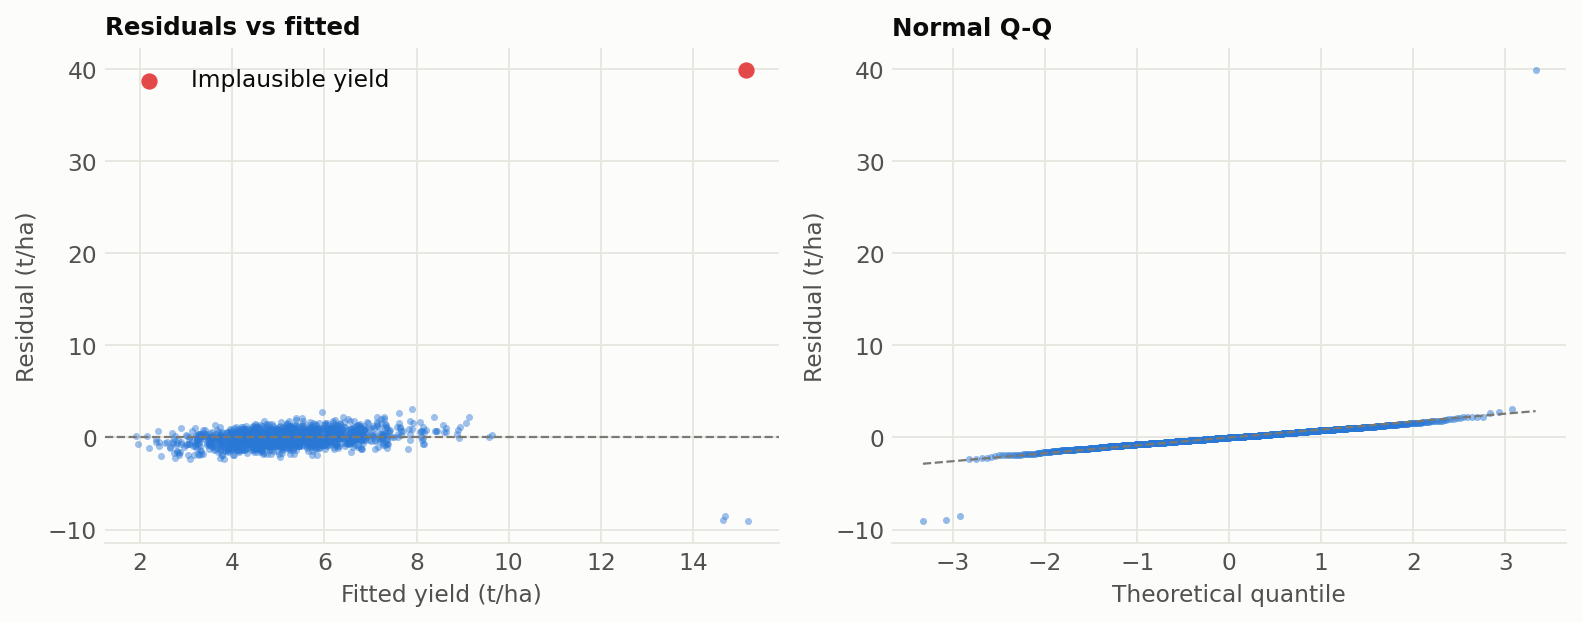

,component,variance,share
0,Between fields (random intercept),1.575,0.423
1,Within field (residual),2.150,0.577


In [11]:
res = analysis.residual_frame(df)
plotting.residual_diagnostics(res, OUT.figures / "residual_diagnostics.png")
display(Image(OUT.figures / "residual_diagnostics.png", width=820))
te["variance"]

Apart from the single implausible plot, the residuals are centred and roughly symmetric. About 40% of the yield variance lies between fields, which confirms that the random field effect is needed.

## 8. Other management factors

Adding compost, seed rate, DAP and germination rate to the mixed model:

In [12]:
import warnings
warnings.filterwarnings("ignore")

analysis.agronomic_drivers(df)

,variable,effect_per_unit,se,ci_low,ci_high,p_value,n_obs
0,compost_tha,1.688e-02,0.023,-0.027,0.061,0.456,1582
1,seeds_kgha,-4.152e-03,0.011,-0.025,0.017,0.696,1582
2,germination_rate,-8.004e-04,0.005,-0.011,0.010,0.881,1582


None of these has a significant effect: compost, seed rate and germination rate all have p > 0.4. DAP is left out because every plot received the same 100 kg/ha, so its effect cannot be estimated. Adding them does not change the treatment estimates.

## Conclusion

| Question | Answer |
|---|---|
| Highest-yielding treatment | **D: 100 kg/ha all at V6** (+0.55 t/ha, p < 0.001); C equivalent (p = 1.00 vs D) |
| Best per mega-environment | D in all four; also better than C in the Highlands and Low-Mid-Dry (p ≈ 0.05) |
| Do effects differ by environment or season? | No (p = 0.08 and p = 0.10) |
| Robust to the implausible yield? | Yes for D; C's gain falls to +0.38 t/ha |

**Next:** notebook 05 adds rainfall and soil data.